# Rays and invisible lenses: the geometrical optics of cloaking

How much of invisibility can be read off from rays alone? This notebook traces rays through graded-index media, designs lenses from a prescribed deflection function, builds the conformal-map cloak on two Riemann sheets, and then shows the one thing that rays hide: the optical path delay. No wavelength appears anywhere; the lens radius is 1.

**What this notebook shows**

- One ray tracer (Newtonian form of Fermat's principle, DOP853, derivatives from `jax.grad`) reproduces the Luneburg lens, Maxwell's fish-eye, the Eaton lens and the invisible sphere, each with a quantitative check of its defining property.
- The deflection function $\chi(b)$ computed from traced rays agrees with its quadrature, and Luneburg's inversion turns a prescribed $\chi(b)$ back into an index profile (round trips, plus a new right-angle bender and the way the construction fails).
- The conformal cloak on the Zhukovski map is constructed on the lower sheet with a Kepler profile; every statement the construction rests on is verified numerically.
- Rays through the invisible sphere all share one optical path excess, and rays through the conformal cloak are delayed by a fixed amount: what this implies for waves is stated, not computed here (notebook 04 computes it for the cylinder and, with scalar waves, for the sphere).

**Conventions.** Time dependence $e^{-i\omega t}$ (not used by the ray calculations, fixed for the sibling notebooks). Lengths are in lens radii here; the free-space wavelength does not enter. The polarization with $E$ along $z$ is called TM ($E_z$), as in the project's `DESIGN.md`; the book calls it TE. Rays are polarization independent, so the label only matters from notebook 02 on. Book references are by section and equation number of Leonhardt and Philbin, *Geometry and Light* (Dover 2010). The deflection $\chi$ is counted positive when the ray bends toward the center; the book counts it negative in that case, so its formulas appear below with the sign of $\chi$ flipped.

In [1]:
import os
for _v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ.setdefault(_v, "4")  # keep the machine usable; must run before numpy is imported

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from cycler import cycler
import jax
import jax.numpy as jnp

jax.config.update("jax_enable_x64", True)

# Figure style shared by every notebook in notebooks/cloaking (do not edit per notebook).
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]  # series colors, fixed order
INK, INK2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list(  # magnitudes: one hue, light to dark
    "seq_blue", ["#eef4fc", "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list(  # signed quantities: blue, neutral gray, red; use symmetric limits
    "div_blue_red", ["#0d366b", "#256abf", "#6da7ec", "#f0efec", "#ee8f8e", "#d03b3b", "#7d1919"])
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "figure.figsize": (6.4, 4.0),
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.titlesize": 10, "axes.labelsize": 10,
    "legend.fontsize": 9, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": cycler(color=CAT), "lines.linewidth": 1.6, "lines.markersize": 5.5,
    "legend.frameon": False, "image.origin": "lower", "image.interpolation": "nearest", "image.cmap": "seq_blue",
    "figure.constrained_layout.use": True,
})
plt.colormaps.register(SEQ, force=True)
plt.colormaps.register(DIV, force=True)


def check(name, value, tol, target=0.0):
    """Print PASS or FAIL for |value - target| <= tol and assert it, so a rerun catches regressions."""
    err = abs(value - target)
    print(f"{'PASS' if err <= tol else 'FAIL'}  {name}: got {value:.6g}, target {target:.6g}, |diff| {err:.2e} <= {tol:.0e}")
    assert err <= tol, name

In [2]:
from scipy.integrate import solve_ivp, quad
from scipy.interpolate import CubicSpline
from scipy.optimize import brentq, minimize_scalar
from numpy.polynomial.legendre import leggauss
from matplotlib.colors import LogNorm

## 1. Ray equations

Fermat's principle with the parameter $\mathrm d\xi = \mathrm dl/n$ (book section 3, eqs. (3.4)-(3.6)) turns rays into trajectories of a unit-mass particle:

$$\frac{\mathrm d^2\mathbf r}{\mathrm d\xi^2} = \nabla\frac{n^2}{2}, \qquad \left|\frac{\mathrm d\mathbf r}{\mathrm d\xi}\right| = n .$$

The speed condition is a constraint that the flow preserves (energy conservation, (3.8)-(3.9)). For central $n(r)$ the angular momentum $x p_y - y p_x$ is also conserved, (3.11)-(3.12). Two extra quantities ride along in the state: the optical path $\int n\,\mathrm dl = \int n^2\,\mathrm d\xi$ and the turning angle of $\mathbf p$, so that deflection angles larger than $\pi$ need no unwrapping. The right-hand side is built from `jax.grad` of $n^2(x,y)$ and jitted; the integrator is `scipy` DOP853. The test below compares it with a closed form: for $n^2 = 1 + 2gy$ the momentum obeys $\dot p_y = g$ exactly.

In [3]:
def field(n2, weight=None):
    """Jitted right-hand side of d2r/dxi2 = grad(n^2/2) for s = (x, y, px, py, opl, turn), p = dr/dxi.
    opl = integral of n dl = integral of n^2 dxi; turn = running angle of p. weight(x, y) optionally
    reparametrizes dxi = weight ds (a Sundman time), which only changes the step sizes."""
    g = jax.grad(n2, argnums=(0, 1))
    @jax.jit
    def rhs(s):
        x, y, px, py = s[0], s[1], s[2], s[3]
        fx, fy = g(x, y)
        fx, fy = 0.5 * fx, 0.5 * fy
        w = 1.0 if weight is None else weight(x, y)
        return w * jnp.stack([px, py, fx, fy, px**2 + py**2, (px * fy - py * fx) / (px**2 + py**2)])
    return lambda t, s: np.asarray(rhs(s))

SPEC = dict(rtol=1e-10, atol=1e-12)     # tolerances of the brief
TIGHT = dict(rtol=3e-14, atol=1e-20)    # for the profiles that are singular at r = 0 (section 2)

def trace(rhs, s0, t_max=200.0, events=None, tol=SPEC):
    """DOP853 integration of the ray system from state s0; returns the solve_ivp result with dense output."""
    sol = solve_ivp(rhs, (0.0, t_max), np.asarray(s0, float), method="DOP853", events=events, dense_output=True, **tol)
    assert sol.status >= 0, sol.message
    return sol

def samples(sol, per_step=4):
    """Points along a traced ray: per_step dense-output samples inside every accepted step."""
    t = sol.t
    tt = np.concatenate([(t[:-1, None] + np.diff(t)[:, None] * np.linspace(0, 1, per_step, endpoint=False)).ravel(), t[-1:]])
    return sol.sol(tt)

# test against a closed form: n^2 = 1 + 2 g y gives dpy/dxi = g, so y = y0 + py0 xi + g xi^2 / 2
gg = 0.7
rhs_lin = field(lambda x, y: 1.0 + 2.0 * gg * y)
sol = trace(rhs_lin, [0, 0.2, 1.0, 0.3, 0, 0], t_max=3.0)
xi = sol.t[-1]
err = max(abs(sol.y[1, -1] - (0.2 + 0.3 * xi + gg * xi**2 / 2)), abs(sol.y[3, -1] - (0.3 + gg * xi)), abs(sol.y[0, -1] - xi))
check("tracer vs closed form (linear n^2), max error", err, 1e-9)  # rtol 1e-10 over a path of length ~3

PASS  tracer vs closed form (linear n^2), max error: got 1.77636e-15, target 0, |diff| 1.78e-15 <= 1e-09


## 2. Four classic profiles

All four lenses have radius 1 and $n = 1$ outside, with $n$ continuous at $r=1$:

- **Luneburg lens** (book (3.14), (9.10)): $n=\sqrt{2-r^2}$. Parallel rays focus on the rim.
- **Maxwell fish-eye** (book (9.13)): $n = 2/(1+r^2)$ on the whole plane. Light moves on great circles of a virtual sphere (stereographic projection), so rays from $\mathbf r_0$ all meet at the antipodal image $-\mathbf r_0/|\mathbf r_0|^2$, book (9.33).
- **Eaton lens** (book (6.8)): $n=\sqrt{2/r-1}$. Orbits are Kepler ellipses; every ray is turned back.
- **Invisible sphere** (book (9.4)-(9.6), $\nu = 1$): $n$ is the root of $(1+n)^2 n r^2 = 4$. The book prints the cubic with $r$ instead of $r^2$ (ERRATA E2.1); with $q=\sqrt n$ it reads $q^3+q=2/r$. Closed form and its stable evaluation are in the code.

The Eaton lens and the invisible sphere are singular at $r=0$ ($n\sim r^{-1/2}$ and $n\sim r^{-2/3}$), so the central ray is never launched there (smallest $|b|=0.05$). Even so, near the center the integrator has to follow a very small, very fast loop. The second table printed by the ray-tracing cell shows what that costs and what was done about it: the singular profiles are traced with a tighter tolerance and the time reparametrization $\mathrm d\xi = r\,\mathrm ds$, which does not change the rays. The invariants are reported as relative drifts, $|\,|p|^2-n^2|/n^2$ and the drift of $L$ divided by $|L|$, because $n^2$ spans many orders of magnitude.

In [4]:
# --- the four profiles (xp is numpy or jax.numpy so that the same formula serves the tracer and the quadratures) ---
def n_luneburg(r, xp=jnp): return xp.sqrt(2.0 - r**2)
def n_fisheye(r, xp=jnp): return 2.0 / (1.0 + r**2)
def n_eaton(r, xp=jnp): return xp.sqrt(2.0 / r - 1.0)
def n_invisible(r, xp=jnp):
    """q = sqrt(n) solves q^3 + q = 2/r. With Q = cbrt(1/r + sqrt(1/r^2 + 1/27)) the second cube root of the
    closed form is -1/(3Q), because the two radicands multiply to -1/27; q = Q - 1/(3Q) is the same number
    without the cancellation that loses digits in the printed form (about 6e-7 relative at r = 1e-9)."""
    Q = xp.cbrt(1.0 / r + xp.sqrt(1.0 / r**2 + 1.0 / 27.0))
    return (Q - 1.0 / (3.0 * Q))**2

NAMES = ["Luneburg lens", "Maxwell fish-eye (cut at r = 1)", "Eaton lens", "invisible sphere"]
NFUN = dict(zip(NAMES, [n_luneburg, n_fisheye, n_eaton, n_invisible]))
PCOL = dict(zip(NAMES, CAT[:4]))                 # one color per profile in every figure
CHI_EXACT = {"Luneburg lens": np.arcsin, "Maxwell fish-eye (cut at r = 1)": lambda b: 2 * np.arcsin(b),
             "Eaton lens": lambda b: np.pi + 0 * b, "invisible sphere": lambda b: 2 * np.pi + 0 * b}
SINGULAR = {"Eaton lens", "invisible sphere"}
n2_of = lambda nf: (lambda x, y: nf(jnp.sqrt(x**2 + y**2))**2)
RHS = {k: field(n2_of(NFUN[k]), weight=(lambda x, y: jnp.sqrt(x**2 + y**2)) if k in SINGULAR else None) for k in NAMES}
TOL = {k: TIGHT if k in SINGULAR else SPEC for k in NAMES}

def lens_ray(name, b, rhs=None, tol=None):
    """Ray y = b traveling in +x, started on the rim (n = 1 there) and traced until it leaves the unit disk."""
    ev = lambda t, s: s[0]**2 + s[1]**2 - 1.0
    ev.terminal, ev.direction = True, 1
    sol = trace(rhs or RHS[name], [-np.sqrt(1 - b * b), b, 1.0, 0.0, 0.0, 0.0], t_max=1e4, events=ev, tol=tol or TOL[name])
    assert sol.status == 1
    return sol

def invariants(sol, nfun):
    """Relative drift of |p|^2 - n^2 and of the angular momentum x py - y px along a traced ray."""
    x, y, px, py = sol.y[:4]
    n2 = nfun(np.hypot(x, y), np) ** 2
    L = x * py - y * px
    return np.max(np.abs(px**2 + py**2 - n2) / n2), np.max(np.abs(L - L[0])) / abs(L[0])

# the implicit equation of the invisible sphere
r = np.geomspace(1e-3, 1, 400)
nn = n_invisible(r, np)
check("invisible sphere: n(1) - 1", float(n_invisible(1.0, np)) - 1.0, 1e-14)  # exact root q = 1
check("invisible sphere: max relative residual of (1+n)^2 n r^2 = 4", np.max(np.abs((1 + nn)**2 * nn * r**2 / 4 - 1)), 1e-12)  # cbrt accuracy ~1e-15, amplified by 1/r
check("invisible sphere: max relative residual of q^3 + q = 2/r", np.max(np.abs((nn**1.5 + nn**0.5) * r / 2 - 1)), 1e-12)
r1 = 1e-9  # next term of the expansion: n = (2/r)^(2/3) - 2/3 + ..., so the relative size of the correction is (2/3)(r/2)^(2/3)
check("invisible sphere: n / (2/r)^(2/3) at r = 1e-9 against 1 - (2/3)(r/2)^(2/3)", float(n_invisible(r1, np)) / (2 / r1)**(2 / 3), 1e-9, target=1 - 2 / 3 * (r1 / 2)**(2 / 3))  # next term of the expansion; the remainder is O(r^(4/3)) ~ 1e-12
print("  (the predicted size of the correction is %.1e)" % (2 / 3 * (r1 / 2)**(2 / 3)))

PASS  invisible sphere: n(1) - 1: got 0, target 0, |diff| 0.00e+00 <= 1e-14
PASS  invisible sphere: max relative residual of (1+n)^2 n r^2 = 4: got 1.66533e-15, target 0, |diff| 1.67e-15 <= 1e-12
PASS  invisible sphere: max relative residual of q^3 + q = 2/r: got 6.66134e-16, target 0, |diff| 6.66e-16 <= 1e-12
PASS  invisible sphere: n / (2/r)^(2/3) at r = 1e-9 against 1 - (2/3)(r/2)^(2/3): got 1, target 1, |diff| 4.53e-14 <= 1e-09
  (the predicted size of the correction is 4.2e-07)


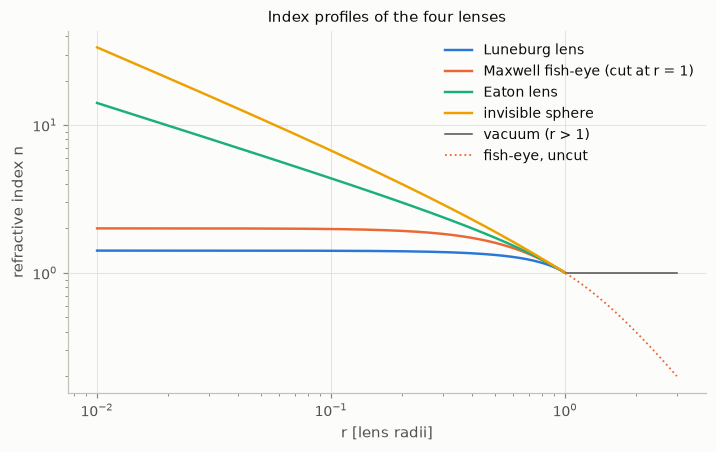

In [5]:
# --- profiles on one log axis ---
fig, ax = plt.subplots(figsize=(6.4, 4.0))
rr = np.geomspace(1e-2, 3, 600)
for name in NAMES:
    ax.plot(rr[rr <= 1], NFUN[name](rr[rr <= 1], np), color=PCOL[name], label=name)
ax.plot(rr[rr > 1], np.ones((rr > 1).sum()), color=INK2, lw=1.0, label="vacuum (r > 1)")
ax.plot(rr[rr > 1], n_fisheye(rr[rr > 1], np), color=PCOL["Maxwell fish-eye (cut at r = 1)"], ls=":", lw=1.2, label="fish-eye, uncut")
ax.set(xscale="log", yscale="log", xlabel="r [lens radii]", ylabel="refractive index n", title="Index profiles of the four lenses"); ax.legend(); plt.show()

In [6]:
# --- trace the fans and collect the invariants ---
BS = np.linspace(-0.95, 0.95, 20)                      # 20 impact parameters, none equal to zero
FAN = {}
for name in NAMES:
    bs = BS if name not in SINGULAR else BS[np.abs(BS) >= 0.05]   # never launch the central ray of a singular profile
    FAN[name] = (bs, [lens_ray(name, b) for b in bs])
print(f"{'profile':34s}{'rays':>5s}{'steps (max)':>13s}{'|p|^2 - n^2':>14s}{'ang. mom.':>12s}")
for name in NAMES:
    inv = np.array([invariants(s, NFUN[name]) for s in FAN[name][1]])
    print(f"{name:34s}{len(inv):5d}{max(len(s.t) for s in FAN[name][1]):13d}{inv[:, 0].max():14.1e}{inv[:, 1].max():12.1e}")
    check(f"{name}: constraint |p|^2 = n^2 (relative drift)", inv[:, 0].max(), 1e-8)   # DOP853 at the quoted tolerances; see the sensitivity table below
    check(f"{name}: angular momentum (relative drift)", inv[:, 1].max(), 1e-8)

print("\nWhy the singular profiles are traced differently: worst ray b = 0.05, invisible sphere")
print(f"{'setting':44s}{'|p|^2 - n^2':>14s}{'|chi - 2 pi|':>14s}")
for label, rhs, tol in [("rtol 1e-10, atol 1e-12, dxi = ds", field(n2_of(n_invisible)), SPEC),
                        ("rtol 1e-10, atol 1e-12, dxi = r ds", RHS["invisible sphere"], SPEC),
                        ("rtol 3e-14, atol 1e-20, dxi = r ds (used)", RHS["invisible sphere"], TIGHT)]:
    s = lens_ray("invisible sphere", 0.05, rhs=rhs, tol=tol)
    print(f"{label:44s}{invariants(s, n_invisible)[0]:14.1e}{abs(-s.y[5, -1] - 2 * np.pi):14.1e}")

profile                            rays  steps (max)   |p|^2 - n^2   ang. mom.
Luneburg lens                        20           13       1.4e-11     6.9e-12
PASS  Luneburg lens: constraint |p|^2 = n^2 (relative drift): got 1.38175e-11, target 0, |diff| 1.38e-11 <= 1e-08
PASS  Luneburg lens: angular momentum (relative drift): got 6.90898e-12, target 0, |diff| 6.91e-12 <= 1e-08
Maxwell fish-eye (cut at r = 1)      20           22       1.8e-10     5.3e-11
PASS  Maxwell fish-eye (cut at r = 1): constraint |p|^2 = n^2 (relative drift): got 1.7768e-10, target 0, |diff| 1.78e-10 <= 1e-08
PASS  Maxwell fish-eye (cut at r = 1): angular momentum (relative drift): got 5.28374e-11, target 0, |diff| 5.28e-11 <= 1e-08
Eaton lens                           19          213       9.9e-13     3.5e-13
PASS  Eaton lens: constraint |p|^2 = n^2 (relative drift): got 9.85212e-13, target 0, |diff| 9.85e-13 <= 1e-08
PASS  Eaton lens: angular momentum (relative drift): got 3.45582e-13, target 0, |diff| 3.46e-1

rtol 3e-14, atol 1e-20, dxi = r ds (used)          2.4e-09       9.6e-11


The checks that define each lens follow. Everything is measured on the traced rays: the Luneburg focus on the rim, retro-reflection by the Eaton lens, and for the invisible sphere that every ray leaves on the continuation of its incoming line. The fish-eye rays are circles through the image point; the circle fit and the miss distance are two independent views of the same fact.

In [7]:
# --- focusing / retro-reflection / invisibility checks ---
def exit_state(sol):
    x, y, px, py = sol.y[:4, -1]
    return np.array([x, y]), np.array([px, py]) / np.hypot(px, py)      # n = 1 on the rim, so p is a unit vector

bs, sols = FAN["Luneburg lens"]
miss = max(np.hypot(*(exit_state(s)[0] - [1.0, 0.0])) for s in sols)
check("Luneburg: largest distance from the rim focus (1, 0)", miss, 1e-6)

bs, sols = FAN["Eaton lens"]
err = max(np.hypot(*(exit_state(s)[1] + [1.0, 0.0])) for s in sols)
check("Eaton: exit direction + incoming direction", err, 1e-6)

bs, sols = FAN["invisible sphere"]
derr = max(np.hypot(*(exit_state(s)[1] - [1.0, 0.0])) for s in sols)
oerr = max(abs(exit_state(s)[0][1] - b) for b, s in zip(bs, sols))     # exit point must lie on the line y = b
check("invisible sphere: exit direction error", derr, 1e-6)
check("invisible sphere: lateral offset of the exit line", oerr, 1e-6)

# Maxwell fish-eye on the whole plane: rays from (-0.5, 0) are circles through the image point (2, 0)
SRC, IMG = np.array([-0.5, 0.0]), np.array([2.0, 0.0])
assert np.allclose(-SRC / (SRC @ SRC), IMG)                           # book (9.33)
def fisheye_ray(theta):
    n0 = n_fisheye(0.5, np)
    ev = lambda t, s: abs(s[5]) - 2 * np.pi                           # one full turn of the direction = one lap of the circle
    ev.terminal, ev.direction = True, 1
    return trace(RHS["Maxwell fish-eye (cut at r = 1)"], [*SRC, n0 * np.cos(theta), n0 * np.sin(theta), 0, 0], t_max=500.0, events=ev)

def nearest(sol, pt):
    d = lambda t: np.hypot(*(sol.sol(t)[:2] - pt))
    tt = np.linspace(0, sol.t[-1], 4001)
    k = np.argmin([d(t) for t in tt])
    res = minimize_scalar(d, bounds=(tt[max(k - 1, 0)], tt[min(k + 1, 4000)]), method="bounded", options=dict(xatol=1e-12))
    return res.fun

def circle_residual(P):
    A = np.c_[2 * P[0], 2 * P[1], np.ones(P.shape[1])]                 # algebraic circle fit |P - c|^2 = R^2
    c = np.linalg.lstsq(A, (P**2).sum(0), rcond=None)[0]
    R = np.sqrt(c[2] + c[0]**2 + c[1]**2)
    return np.max(np.abs(np.hypot(P[0] - c[0], P[1] - c[1]) - R)), c[:2], R

FISH_ANG = np.radians([-145, -110, -70, -35, 35, 70, 110, 145])
FISH = [fisheye_ray(t) for t in FISH_ANG]
res = [circle_residual(samples(s, 8)[:2]) for s in FISH]
print(f"{'angle [deg]':>12s}{'miss of image':>16s}{'circle residual':>17s}{'center x':>10s}{'radius':>8s}")
for t, s, (rs, c, R) in zip(FISH_ANG, FISH, res):
    print(f"{np.degrees(t):12.0f}{nearest(s, IMG):16.1e}{rs:17.1e}{c[0]:10.4f}{R:8.4f}")
check("fish-eye: largest distance from the image point", max(nearest(s, IMG) for s in FISH), 1e-6)
check("fish-eye: largest circle-fit residual", max(r[0] for r in res), 1e-6)

PASS  Luneburg: largest distance from the rim focus (1, 0): got 1.05097e-11, target 0, |diff| 1.05e-11 <= 1e-06
PASS  Eaton: exit direction + incoming direction: got 1.47913e-13, target 0, |diff| 1.48e-13 <= 1e-06
PASS  invisible sphere: exit direction error: got 1.80054e-10, target 0, |diff| 1.80e-10 <= 1e-06
PASS  invisible sphere: lateral offset of the exit line: got 6.76165e-11, target 0, |diff| 6.76e-11 <= 1e-06
 angle [deg]   miss of image  circle residual  center x  radius
        -145         5.8e-08          1.5e-09    0.7500  2.1793


        -110         1.1e-09          2.4e-10    0.7500  1.3302
         -70         1.2e-09          3.2e-10    0.7500  1.3302
         -35         5.2e-10          6.8e-09    0.7500  2.1793
          35         5.2e-10          6.8e-09    0.7500  2.1793
          70         1.2e-09          3.2e-10    0.7500  1.3302
         110         1.1e-09          2.4e-10    0.7500  1.3302


         145         5.8e-08          1.5e-09    0.7500  2.1793
PASS  fish-eye: largest distance from the image point: got 5.75918e-08, target 0, |diff| 5.76e-08 <= 1e-06
PASS  fish-eye: largest circle-fit residual: got 6.81308e-09, target 0, |diff| 6.81e-09 <= 1e-06


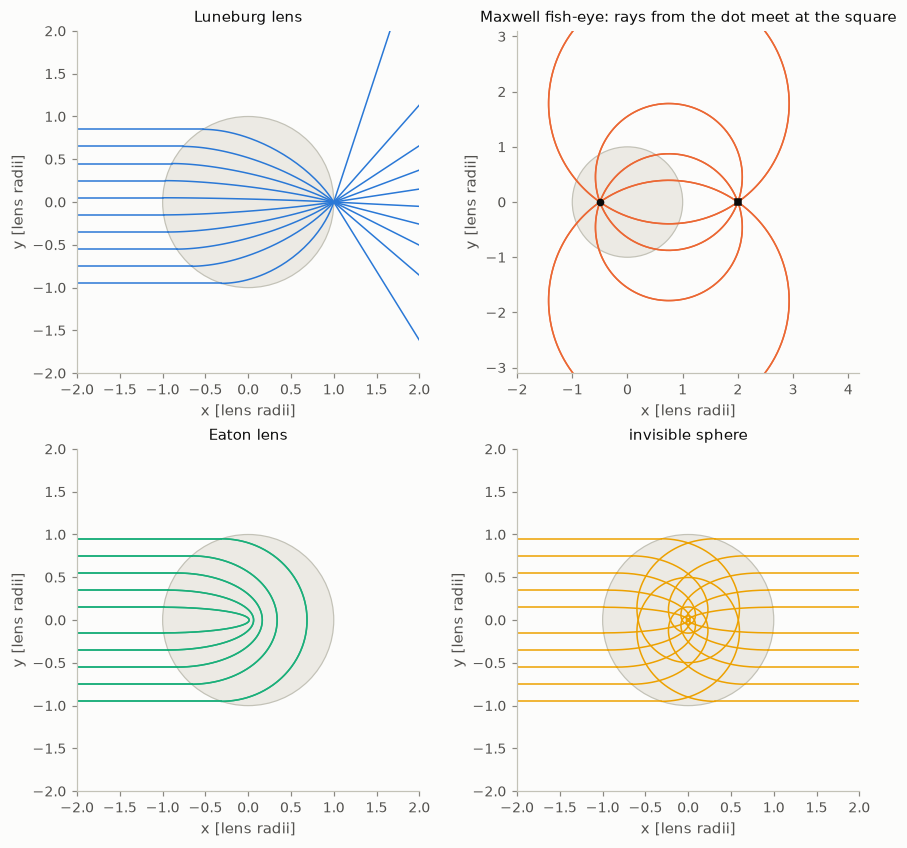

In [8]:
# --- 2 x 2 ray fans ---
def fan_panel(ax, name, lim=2.0):
    col = PCOL[name]
    ax.add_patch(plt.Circle((0, 0), 1, fc="#eceae4", ec=AXIS, lw=0.8, zorder=0))
    bs, sols = FAN[name]
    for b, s in zip(bs[::2], sols[::2]):
        P = samples(s)[:2]
        x0 = -lim
        pe, de = exit_state(s)
        ax.plot([x0, P[0, 0]], [b, b], color=col, lw=1.0)
        ax.plot(P[0], P[1], color=col, lw=1.0)
        ax.plot([pe[0], pe[0] + (lim + 0.5) * de[0]], [pe[1], pe[1] + (lim + 0.5) * de[1]], color=col, lw=1.0)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect="equal", title=name, xlabel="x [lens radii]", ylabel="y [lens radii]"); ax.grid(False)

fig, axs = plt.subplots(2, 2, figsize=(8.0, 7.6))
for ax, name in zip(axs.ravel(), NAMES):
    if name.startswith("Maxwell"):
        ax.add_patch(plt.Circle((0, 0), 1, fc="#eceae4", ec=AXIS, lw=0.8, zorder=0))
        for s in FISH:
            P = samples(s, 8)[:2]
            ax.plot(P[0], P[1], color=PCOL[name], lw=1.0)
        ax.plot(*SRC, "o", color=INK, ms=4); ax.plot(*IMG, "s", color=INK, ms=4)
        ax.set(xlim=(-2, 4.2), ylim=(-3.1, 3.1), aspect="equal", title="Maxwell fish-eye: rays from the dot meet at the square", xlabel="x [lens radii]", ylabel="y [lens radii]"); ax.grid(False)
    else:
        fan_panel(ax, name)
plt.show()

## 3. The deflection function

For a central profile with turning point $n(r_t)\,r_t=b$, the bending angle toward the center is

$$\chi(b) = 2\int_{r_t}^{\infty}\frac{b\,\mathrm dr}{r\sqrt{n^2r^2-b^2}} - \pi$$

(book (8.1) with the opposite sign). A free ray gives 0, the Eaton lens $\pi$, the invisible sphere $2\pi$. The part outside the lens is $\arcsin b$ in closed form. Inside, the substitution $\ln r = \ln r_t + s^2$ removes the square-root singularity at the turning point. Two further closed forms serve as cross-checks: $\chi=\arcsin b$ for the Luneburg lens and $2\arcsin b$ for the cut fish-eye (book section 9, (9.7)-(9.12): $\chi$ is minus the sum of the two end angles). The rays give $\chi$ independently as the total turning angle of $\mathbf p$.

PASS  quadrature on a free ray (n = 1): chi: got 2.75531e-11, target 0, |diff| 2.76e-11 <= 1e-09
profile                             ray vs quad  quad vs exact
Luneburg lens                           2.1e-10        1.1e-10
PASS  Luneburg lens: chi from rays vs quadrature: got 2.12317e-10, target 0, |diff| 2.12e-10 <= 1e-06
PASS  Luneburg lens: chi from quadrature vs closed form: got 1.08888e-10, target 0, |diff| 1.09e-10 <= 1e-08
Maxwell fish-eye (cut at r = 1)         1.0e-09        1.1e-10
PASS  Maxwell fish-eye (cut at r = 1): chi from rays vs quadrature: got 1.0064e-09, target 0, |diff| 1.01e-09 <= 1e-06
PASS  Maxwell fish-eye (cut at r = 1): chi from quadrature vs closed form: got 1.08661e-10, target 0, |diff| 1.09e-10 <= 1e-08


Eaton lens                              2.2e-10        2.2e-10
PASS  Eaton lens: chi from rays vs quadrature: got 2.18778e-10, target 0, |diff| 2.19e-10 <= 1e-06
PASS  Eaton lens: chi from quadrature vs closed form: got 2.18574e-10, target 0, |diff| 2.19e-10 <= 1e-08


invisible sphere                        1.9e-09        1.9e-09
PASS  invisible sphere: chi from rays vs quadrature: got 1.856e-09, target 0, |diff| 1.86e-09 <= 1e-06
PASS  invisible sphere: chi from quadrature vs closed form: got 1.85607e-09, target 0, |diff| 1.86e-09 <= 1e-08


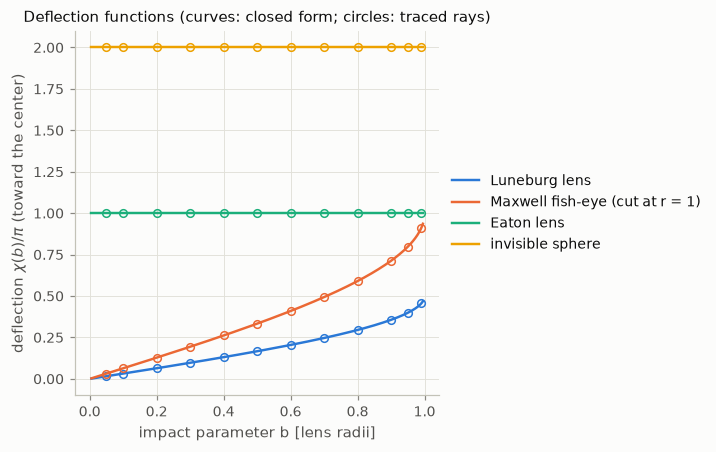

In [9]:
# --- deflection function by quadrature: chi(b) = 2 [arcsin b + int_{r_t}^1 b dr / (r sqrt(n^2 r^2 - b^2))] - pi ---
SX, SW = leggauss(160)
def chi_quad(nfun, b):
    """Bending angle toward the center. The outside part is arcsin(b) in closed form. Inside, u = ln r and
    u = u_t + s^2 remove the 1/sqrt singularity at the turning point r_t, where n(r_t) r_t = b."""
    rho = lambda r: nfun(r, np) * r
    rt = brentq(lambda r: rho(r) - b, 1e-14, 1.0, xtol=1e-300, rtol=1e-15)   # rho(r) = n r is increasing on (0, 1] for all four
    ut = np.log(rt)
    if ut >= 0:
        return 2.0 * np.arcsin(b) - np.pi + 2.0 * (np.pi / 2 - np.arcsin(b))
    smax = np.sqrt(-ut)
    s = 0.5 * smax * (SX + 1)
    r = np.exp(ut + s * s)
    d = rho(r) - rho(rt)                                      # measured from rho(r_t), so the difference vanishes consistently at s = 0
    inner = np.sum(0.5 * smax * SW * 2.0 * s * b / np.sqrt(d * (rho(r) + rho(rt))))
    return 2.0 * (np.arcsin(b) + inner) - np.pi

BCHI = np.array([0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95, 0.99])
free = lambda r, xp=np: 1.0 + 0.0 * r
check("quadrature on a free ray (n = 1): chi", max(abs(chi_quad(free, b)) for b in BCHI), 1e-9)   # the check has to be zero up to the 160-point Gauss-Legendre accuracy (about 1e-10)
CHI = {}
print(f"{'profile':34s}{'ray vs quad':>13s}{'quad vs exact':>15s}")
for name in NAMES:
    cq = np.array([chi_quad(NFUN[name], b) for b in BCHI])
    cr = np.array([-lens_ray(name, b).y[5, -1] for b in BCHI])      # turn is counterclockwise; the ray at y = b > 0 bends clockwise
    CHI[name] = (cq, cr)
    e1, e2 = np.max(np.abs(cr - cq)), np.max(np.abs(cq - CHI_EXACT[name](BCHI)))
    print(f"{name:34s}{e1:13.1e}{e2:15.1e}")
    check(f"{name}: chi from rays vs quadrature", e1, 1e-6)      # ray tolerances give ~1e-9; 1e-6 is the target of the brief
    check(f"{name}: chi from quadrature vs closed form", e2, 1e-8)   # 160-point Gauss-Legendre; worst near b = 0.99, where the integrand is steepest

fig, ax = plt.subplots(figsize=(6.4, 4.0))
bb = np.linspace(0.005, 0.995, 300)
for name in NAMES:
    ax.plot(bb, CHI_EXACT[name](bb) / np.pi, color=PCOL[name], label=name)
    ax.plot(BCHI, CHI[name][1] / np.pi, "o", color=PCOL[name], mfc="none", ms=5)
ax.set(xlabel="impact parameter b [lens radii]", ylabel=r"deflection $\chi(b)/\pi$ (toward the center)", title="Deflection functions (curves: closed form; circles: traced rays)")
ax.legend(loc="center left", bbox_to_anchor=(1.0, 0.5)); plt.show()

## 4. Designing a lens from its deflection function

Luneburg's inversion (book section 8, (8.12)-(8.16)) recovers the index from $\chi(b)$ by an Abel transform. With the turning parameter $\rho=nr$ and the lens radius 1,

$$\ln n(\rho) = \frac1\pi\int_\rho^1 \frac{\chi(b)\,\mathrm db}{\sqrt{b^2-\rho^2}}, \qquad r = \frac{\rho}{n(\rho)} .$$

This is the book's (8.15)-(8.16) with $\chi$ counted positive inward. The misprinted sign in (8.18)-(8.19) (ERRATA E1.4) concerns the companion formula for bound orbits, which is not needed here. For constant $\chi=k\pi$ the integral is elementary, $n = \bigl((1+\sqrt{1-\rho^2})/\rho\bigr)^{k}$, which gives book (9.3) with $k=2\nu$.

Numerically, with $\rho = 1/\cosh u$ and $b=\rho\cosh v$, $v=u(1-t^2)$, both the $1/\sqrt{}$ singularity at $b=\rho$ and the square-root behavior of $\chi$ at $b=1$ disappear, and a short Gauss-Legendre rule suffices. Three tests: (a) $\chi=\pi$ and $2\pi$ must return the Eaton lens and the invisible sphere; (b) the Luneburg lens must come back from its own computed $\chi(b)$; (c) the new bender $\chi=\pi/2$ must deflect traced rays by a right angle.

The construction needs $\rho(r)$ to be single valued, so $r(\rho)$ must increase with $\rho$, and the profile must lie inside the lens, $r\le1$ (outside, $n=1$): otherwise no medium has that $\chi$. Book section 8 discusses non-existence and non-uniqueness (its Fig. 2.32 shows $\rho(r)$ for the family (9.3), multivalued for negative $\nu$). For constant $\chi$ the derivative is $\mathrm d\ln r/\mathrm d\rho = (s+k)/(s\rho)$ with $s=\sqrt{1-\rho^2}$, so for $-1<k<0$ the profile turns back near the rim (where $r(\rho)$ exceeds 1 and then decreases), and for $k\le-1$ it is monotonic but decreasing and lies entirely in $r\ge1$. For constant $\chi=k\pi$ the construction therefore works exactly when $k>0$. The reason a constant $k<0$ cannot be realized by any medium is general: for a central medium with $n=1$ outside the unit circle, the deflection is $\chi(b)=2\arcsin b-\pi+2\int_{r_t}^{1} b\,\mathrm dr\big/\bigl(r\sqrt{\rho^2-b^2}\bigr)$ with a non-negative integral, so $\chi(1^-)\ge0$. Diverging lenses are not excluded in general: a deflection that is negative inside and tends to zero at the rim can be built, and the cell below does so for $\chi=-0.3\pi(1-b^2)$.

In [10]:
# --- Luneburg's inversion: ln n(rho) = (1/pi) int_rho^1 chi(b) db / sqrt(b^2 - rho^2),  r = rho / n ---
GLX, GLW = leggauss(48)
GLX, GLW = 0.5 * (GLX + 1), 0.5 * GLW                      # Gauss-Legendre nodes on [0, 1]

def design(chi, u):
    """Profile at the turning parameters rho = 1/cosh(u), u >= 0 (u = 0 is the rim). Here b = rho cosh v with
    v in [0, u] removes the 1/sqrt singularity, and v = u (1 - t^2) removes the sqrt in chi(b) at b = 1
    (chi is smooth in t). Returns arrays rho, n, r."""
    u = np.atleast_1d(np.asarray(u, float))
    lnn = np.zeros_like(u)
    for i, ui in enumerate(u):
        if ui > 0:
            b = np.cosh(ui * (1 - GLX**2)) / np.cosh(ui)
            lnn[i] = np.dot(GLW, chi(b) * 2 * ui * GLX) / np.pi
    rho = 1 / np.cosh(u)
    n = np.exp(lnn)
    return rho, n, rho / n

U = np.linspace(0, 7, 71)                                    # rho from 1 down to about 2 / e^7
const = lambda c: (lambda b: c + 0 * b)
rho, n, r = design(const(np.pi), U)
e_eaton = np.max(np.abs(n / n_eaton(r, np) - 1))
rho, n, r = design(const(2 * np.pi), U)
e_inv = np.max(np.abs(n / n_invisible(r, np) - 1))
check("recovered Eaton lens from chi = pi: max relative error of n(r)", e_eaton, 1e-8)
check("recovered invisible sphere from chi = 2 pi: max relative error of n(r)", e_inv, 1e-8)

# round trip: Luneburg lens -> its own deflection function from the quadrature -> profile.
# chi(b) is smooth in g = sqrt(1 - b); chi_quad loses accuracy within 1e-4 of the rim (b -> 1), so the quadrature is
# evaluated at Chebyshev nodes in g on [0.02, 1] and fitted by a polynomial that is evaluated down to g = 0.
gn = 0.02 + 0.98 * (1 - np.cos(np.pi * (np.arange(30) + 0.5) / 30)) / 2
poly = np.polynomial.Chebyshev.fit(gn, [chi_quad(n_luneburg, 1 - g * g) for g in gn], 12, domain=[0.02, 1.0])
chi_lun = lambda b: poly(np.sqrt(1 - b))
bt = np.linspace(0.0, 0.9999, 500)
check("Luneburg chi(b): interpolant vs arcsin(b), all b in [0, 0.9999]", np.max(np.abs(chi_lun(bt) - np.arcsin(bt))), 1e-7)
rho, n, r = design(chi_lun, np.linspace(0, 7, 71))
check("Luneburg round trip: max |n(r) - sqrt(2 - r^2)|", np.max(np.abs(n - n_luneburg(r, np))), 1e-6)

PASS  recovered Eaton lens from chi = pi: max relative error of n(r): got 1.33227e-15, target 0, |diff| 1.33e-15 <= 1e-08
PASS  recovered invisible sphere from chi = 2 pi: max relative error of n(r): got 1.9984e-15, target 0, |diff| 2.00e-15 <= 1e-08
PASS  Luneburg chi(b): interpolant vs arcsin(b), all b in [0, 0.9999]: got 1.92606e-08, target 0, |diff| 1.93e-08 <= 1e-07
PASS  Luneburg round trip: max |n(r) - sqrt(2 - r^2)|: got 2.39053e-09, target 0, |diff| 2.39e-09 <= 1e-06


In [11]:
# --- when the construction fails: constant chi = k pi, r(rho) must increase with rho and stay <= 1 ---
KS = [1.0, 0.5, 0.25, -0.25, -0.5, -1.0]
Ufine = np.linspace(0, 7, 701)
print(f"{'chi/pi':>8s}{'r increasing, <= 1':>20s}{'max r over the profile':>24s}{'rho of max':>12s}")
fam = {}
for k in KS:
    rho, n, r = design(const(k * np.pi), Ufine)
    fam[k] = (rho, n, r)
    mono = bool(np.all(np.diff(r) < 0) and r.max() <= 1 + 1e-12)   # u increases as rho decreases; r(rho) increasing and inside the lens
    print(f"{k:8.2f}{str(mono):>20s}{r.max():24.4f}{rho[np.argmax(r)]:12.4f}")
    check(f"chi = {k:g} pi: r(rho) increasing and r <= 1 exactly when chi > 0", float(mono), 0.0, target=float(k > 0))

# a weakly diverging lens that does exist: chi(b) = -c pi (1 - b^2), so chi(1) = 0. Closed form of the inversion:
# ln n = -c [ (1 - rho^2/2) arccosh(1/rho) - sqrt(1 - rho^2)/2 ]
c_div = 0.3
rho, n, r = design(lambda b: -c_div * np.pi * (1 - b**2), Ufine)
A_ = np.arccosh(1 / rho[1:]); s_ = np.sqrt(1 - rho[1:]**2)
lnn_cf = -c_div * ((1 - rho[1:]**2 / 2) * A_ - s_ / 2)
print(f"diverging lens chi = -0.3 pi (1 - b^2): r(rho) increasing and r <= 1: {bool(np.all(np.diff(r) < 0) and r.max() <= 1 + 1e-12)};  max r = {r.max():.6f};  n at the center end = {n[-1]:.4f} (<1)")
check("diverging lens: design() vs closed-form ln n, max abs error", np.max(np.abs(np.log(n[1:]) - lnn_cf)), 1e-8)
check("diverging lens exists: r(rho) increasing and r <= 1", float(bool(np.all(np.diff(r) < 0) and r.max() <= 1 + 1e-12)), 0.0, target=1.0)

# --- a new lens: the right-angle bender, chi = pi/2, built from a spline in (ln r, ln n) and verified by rays ---
rho, n, r = design(const(np.pi / 2), np.linspace(0, 7.5, 301))
cs = CubicSpline(np.log(r)[::-1], np.log(n)[::-1])
xs_j, c_j = jnp.asarray(cs.x), jnp.asarray(cs.c)
def n_bender(rr, xp=jnp):
    x = jnp.log(rr)
    i = jnp.clip(jnp.searchsorted(xs_j, x) - 1, 0, len(xs_j) - 2)
    d = x - xs_j[i]
    return jnp.exp(((c_j[0, i] * d + c_j[1, i]) * d + c_j[2, i]) * d + c_j[3, i])
RHS_B = field(n2_of(n_bender))
BB = np.linspace(0.1, 0.9, 9)
SB = [lens_ray(None, b, rhs=RHS_B, tol=SPEC) for b in BB]
chi_b = np.array([-s.y[5, -1] for s in SB])
print(f"{'b':>6s}{'chi / (pi/2)':>14s}{'turning point r_t':>19s}{'n(r_t)':>9s}")
for b, c, s in zip(BB, chi_b, SB):
    rt = np.min(np.hypot(s.y[0], s.y[1])); print(f"{b:6.2f}{c / (np.pi / 2):14.8f}{rt:19.4f}{float(n_bender(rt)):9.3f}")
check("bender: max |chi - pi/2| over 9 impact parameters", np.max(np.abs(chi_b - np.pi / 2)), 1e-5)   # spline error ~1e-9; the brief asks 1e-5
check("bender: n(1)", float(n_bender(1.0)), 1e-9, target=1.0)
u_03 = brentq(lambda u: np.exp(-u / 2) / np.cosh(u) - 0.3, 0, 7)         # closed form for chi = pi/2: n = e^{u/2}, r = e^{-u/2} / cosh u
check("bender: spline vs closed form n at r = 0.3", float(n_bender(0.3)) / np.exp(u_03 / 2), 1e-6, target=1.0)   # cubic-spline error on 300 knots

  chi/pi  r increasing, <= 1  max r over the profile  rho of max
    1.00                True                  1.0000      1.0000
PASS  chi = 1 pi: r(rho) increasing and r <= 1 exactly when chi > 0: got 1, target 1, |diff| 0.00e+00 <= 0e+00
    0.50                True                  1.0000      1.0000
PASS  chi = 0.5 pi: r(rho) increasing and r <= 1 exactly when chi > 0: got 1, target 1, |diff| 0.00e+00 <= 0e+00
    0.25                True                  1.0000      1.0000
PASS  chi = 0.25 pi: r(rho) increasing and r <= 1 exactly when chi > 0: got 1, target 1, |diff| 0.00e+00 <= 0e+00
   -0.25               False                  1.0321      0.9671
PASS  chi = -0.25 pi: r(rho) increasing and r <= 1 exactly when chi > 0: got 0, target 0, |diff| 0.00e+00 <= 0e+00
   -0.50               False                  1.1398      0.8657
PASS  chi = -0.5 pi: r(rho) increasing and r <= 1 exactly when chi > 0: got 0, target 0, |diff| 0.00e+00 <= 0e+00
   -1.00               False               

     b  chi / (pi/2)  turning point r_t   n(r_t)
  0.10    1.00000001             0.0224    4.464
  0.20    1.00000005             0.0636    3.145
  0.30    1.00000001             0.1180    2.549
  0.40    1.00000002             0.1828    2.189
  0.50    1.00000000             0.2588    1.932
  0.60    0.99999997             0.3466    1.732
  0.70    0.99999988             0.4476    1.564


  0.80    0.99999992             0.5658    1.414
  0.90    0.99999992             0.7126    1.263
PASS  bender: max |chi - pi/2| over 9 impact parameters: got 1.87805e-07, target 0, |diff| 1.88e-07 <= 1e-05
PASS  bender: n(1): got 1, target 1, |diff| 0.00e+00 <= 1e-09
PASS  bender: spline vs closed form n at r = 0.3: got 1, target 1, |diff| 5.43e-10 <= 1e-06


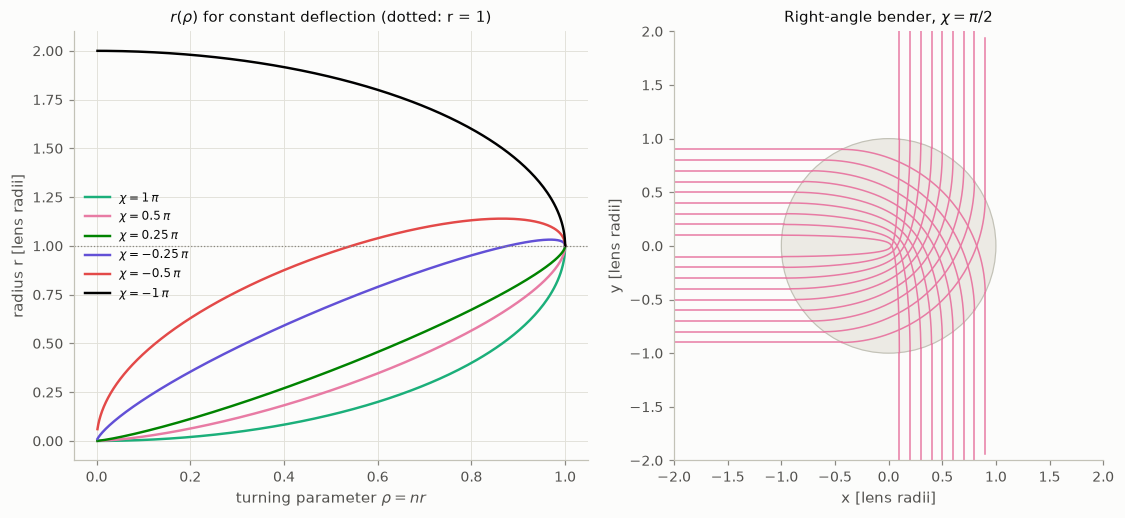

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(10.4, 4.6))
ax = axs[0]
KCOL = {1.0: CAT[2], 0.5: CAT[4], 0.25: CAT[5], -0.25: CAT[6], -0.5: CAT[7], -1.0: "black"}   # chi = pi keeps the Eaton color
for k in KS:
    rho_, n_, r_ = fam[k]
    ax.plot(rho_, r_, color=KCOL[k], label=rf"$\chi = {k:g}\,\pi$")
ax.axhline(1.0, color=MUTED, lw=0.8, ls=":")
ax.set(xlabel=r"turning parameter $\rho = n r$", ylabel="radius r [lens radii]", title=r"$r(\rho)$ for constant deflection (dotted: r = 1)")
ax.legend(fontsize=8)
ax = axs[1]
ax.add_patch(plt.Circle((0, 0), 1, fc="#eceae4", ec=AXIS, lw=0.8, zorder=0))
for b, s in zip(BB, SB):
    for sg in (1, -1):                                        # the lens is symmetric about the x axis: draw both sides
        P = samples(s)[:2] * np.array([[1.0], [sg]])
        pe, de = exit_state(s); pe, de = pe * [1, sg], de * [1, sg]
        ax.plot([-2.0, P[0, 0]], [sg * b, sg * b], color=CAT[4], lw=1.0)
        ax.plot(P[0], P[1], color=CAT[4], lw=1.0)
        ax.plot([pe[0], pe[0] + 1.5 * de[0]], [pe[1], pe[1] + 1.5 * de[1]], color=CAT[4], lw=1.0)
ax.set(xlim=(-2, 2), ylim=(-2, 2), aspect="equal", xlabel="x [lens radii]", ylabel="y [lens radii]", title=r"Right-angle bender, $\chi = \pi/2$"); ax.grid(False)
plt.show()

## 5. The conformal-map cloak

Idea (Leonhardt 2006, book section 5, Fig. 2.19): use the Zhukovski map $w=z+a^2/z$ from the physical plane $z=x+iy$ to a virtual plane $w$, $a=1$. The exterior $|z|>a$ covers the whole $w$-plane (upper sheet); the interior $|z|<a$ covers a second sheet; the two are joined along the cut $[-2a,2a]$, the image of the circle $|z|=a$. A ray that meets the cut would leave the upper sheet and be lost. The physical index is $n(z)=|\mathrm dw/\mathrm dz|\,n'(w)$ (book (5.9)). The book only sketches the profile $n'$ on the lower sheet; here it is constructed.

- **Upper sheet:** $n'=1$, so $n=|1-a^2/z^2|$ outside the circle.
- **Lower sheet:** the Kepler profile $n'^2 = r_0/|w-w_1|-1$ around the branch point $w_1=2a$ (the Eaton/Newton profile of book (6.8), rescaled), with $r_0=8a$.

Why this works. (i) Rays in $n'^2=r_0/\rho-1$ are closed Kepler ellipses with a focus at $w_1$ (book section 6, (6.13); semi-major axis $r_0/2$): a ray that enters returns to its entry point with its entry direction. (ii) A line through a focus meets an ellipse once on each side of the focus. The focus sits at the end of the cut, so exactly one of those points lies on the cut: the ray comes back to the cut once per revolution, at its entry point. (iii) At the cut $p_x$ is conserved while $|p|$ jumps from 1 to $n'$. Entering needs $n'\ge1$ on the whole cut. $n'$ is smallest at the far end $w=-2a$, where $n'^2=r_0/(4a)-1$; the smallest $r_0$ with no total reflection is therefore $r_0=8a$, which also minimizes the loop and, because the hidden region is $|w-w_1|>r_0$, gives the largest hidden region. With $r_0=8a$ the exit refraction restores $|p|=1$ and the same $p_x$, so the ray leaves as if the cut were absent. The optical path of the loop is $\int n'^2\,\mathrm d\xi$ over one period; the virial theorem gives $\langle n'^2\rangle=1$, hence $\pi r_0$ for every ray. Points of the lower sheet with $|w-w_1|>r_0$ are never reached: the hidden region.

The code follows the prescription literally in virtual space (straight line, Snell refraction at the real axis, Kepler orbit with event detection, refraction back, straight line) and then maps to $z$ with the root of $z^2-wz+a^2=0$ outside (upper sheet) or inside (lower sheet) the circle.

In [13]:
# ---------------- section 5: conformal-map cloak ----------------
a_, r0, w1 = 1.0, 8.0, 2.0                                    # Zhukovski radius a, Kepler constant r0 = 8a, branch point w1 = 2a
n2_kepler = lambda x, y: r0 / jnp.sqrt((x - w1)**2 + y**2) - 1.0      # n'^2 = r0 / |w - w1| - 1
RHS_K = field(n2_kepler)
n_cut = lambda x: np.sqrt(r0 / np.abs(x - w1) - 1.0)         # n' on the cut (real w)

def to_z(w, sheet):
    """Inverse Zhukovski map: of the two roots of z + a^2/z = w take the one outside (upper sheet) or inside (lower sheet) the circle."""
    s = np.sqrt(np.asarray(w, complex)**2 - 4 * a_**2)
    z1, z2 = (w + s) / 2, (w - s) / 2
    big = np.where(np.abs(z1) >= np.abs(z2), z1, z2)
    small = np.where(np.abs(z1) >= np.abs(z2), z2, z1)
    return big if sheet == "upper" else small

def cloak_ray(xc, psi, L=6.0):
    """Straight ray with direction angle psi through the point (xc, 0) of the real w axis. If |xc| < 2a it
    meets the cut: Snell refraction onto the lower sheet, Kepler loop, refraction back."""
    d = np.array([np.cos(psi), np.sin(psi)]); sg = np.sign(d[1])
    out = dict(xc=xc, d=d, loop=None)
    if abs(xc) >= 2 * a_:
        out["pre"] = np.c_[[xc, 0] - L * d, [xc, 0] + L * d].T      # misses the cut: one straight line
        return out
    nn = n_cut(xc)
    s0 = [xc, 0.0, d[0], sg * np.sqrt(nn**2 - d[0]**2), 0.0, 0.0]   # p_x is conserved at the cut; |p| jumps from 1 to n'
    first = trace(RHS_K, s0, t_max=0.05)
    ev = lambda t, s: s[1]
    ev.terminal, ev.direction = True, sg                           # return to the cut in the direction of entry
    sol = trace(RHS_K, first.y[:, -1], t_max=500.0, events=ev)
    assert sol.status == 1
    se = sol.y[:, -1]
    pe = np.array([se[2], sg * np.sqrt(1.0 - se[2]**2)])           # refract back: p_x unchanged, |p| = 1
    out.update(s0=np.array(s0), se=se, d_exit=pe, loop=np.c_[samples(first), samples(sol)],
               pre=np.c_[[xc, 0] - L * d, [xc, 0]].T, post=np.c_[[se[0], 0], [se[0], 0] + L * pe].T)
    return out

PSIS = np.radians([-35, -90, -150, 35, 90, 150])               # directions: coming from above (negative) and from below (positive)
XCS = np.linspace(-1.8, 1.8, 6)
RAYS = [cloak_ray(xc, psi) for psi in PSIS for xc in XCS]
print(f"{len(RAYS)} rays through the cut")

36 rays through the cut


In [14]:
def stats(R):
    s0, se, d = R["s0"], R["se"], R["d"]
    return dict(pos=abs(se[0] - s0[0]) + abs(se[1]), mom=np.hypot(se[2] - s0[2], se[3] - s0[3]),
                dir=np.hypot(*(R["d_exit"] - d)), off=abs((se[0] - s0[0]) * d[1]),
                opl=se[4] / (np.pi * r0) - 1.0, reach=np.max(np.hypot(R["loop"][0] - w1, R["loop"][1])))
ST = {k: np.array([stats(R)[k] for R in RAYS]) for k in ["pos", "mom", "dir", "off", "opl", "reach"]}
print(f"{'quantity':52s}{'worst over the rays':>20s}")
rows = [("return point minus entry point", "pos"), ("return momentum minus entry momentum", "mom"), ("exit direction minus entry direction", "dir"),
        ("lateral offset of the exit line", "off"), ("loop optical path / (pi r0) - 1", "opl")]
for lab, k in rows:
    print(f"{lab:52s}{np.max(np.abs(ST[k])):20.1e}")
print(f"{'largest distance |w - w1| reached / r0':52s}{ST['reach'].max() / r0:20.4f}")
check("(1) return point equals entry point", ST["pos"].max(), 1e-8)
check("(1) return momentum equals entry momentum", ST["mom"].max(), 1e-8)
check("(2) exit direction = entry direction", ST["dir"].max(), 1e-8)
check("(2) exit line = entry line (offset)", ST["off"].max(), 1e-8)
check("(3) loop optical path = pi r0 (worst relative error)", np.max(np.abs(ST["opl"])), 1e-8)
check("no ray goes beyond |w - w1| = r0 (excess of the largest reach over r0)", max(ST["reach"].max() - r0, 0.0), 0.0)   # follows from energy conservation: the apocenter is at most r0; the sampled rays only approach it

# (i) the lower-sheet orbits are conics with a focus at w1: 1/rho = A + B cos(phi) + C sin(phi), semi-major axis r0/2
fit_err, axis_err = [], []
for R in RAYS:
    X, Y = R["loop"][0] - w1, R["loop"][1]
    rho_, phi = np.hypot(X, Y), np.arctan2(Y, X)
    M = np.c_[np.ones_like(phi), np.cos(phi), np.sin(phi)]
    cf = np.linalg.lstsq(M, 1 / rho_, rcond=None)[0]
    fit_err.append(np.max(np.abs(M @ cf - 1 / rho_) * rho_))
    ecc = np.hypot(cf[1], cf[2]) / cf[0]
    axis_err.append(1 / cf[0] / (1 - ecc**2) - r0 / 2)
check("(i) orbit is a conic with a focus at w1: worst relative fit error of 1/rho", max(fit_err), 1e-7)
check("(i) semi-major axis equals r0/2: worst deviation", np.max(np.abs(axis_err)), 1e-7)

# (ii) crossings of the real axis, counted along the orbit
def crossings(R):
    x, y = R["loop"][0], R["loop"][1]
    k = np.nonzero(np.sign(y[1:]) * np.sign(y[:-1]) < 0)[0]
    xs = x[k] - y[k] * (x[k + 1] - x[k]) / (y[k + 1] - y[k])
    xs = xs[np.abs(xs - R["s0"][0]) > 1e-6]                 # the entry/return point itself is not a crossing
    return int(np.sum(xs < w1)), int(np.sum(xs > w1))
cr = np.array([crossings(R) for R in RAYS])
print("crossings of the real axis strictly inside the loop (the entry/return point itself is not counted):")
print(f"  on the cut side of w1: {sorted(set(map(int, cr[:, 0])))};  beyond w1, where there is no cut: {sorted(set(map(int, cr[:, 1])))}")
check("(ii) the loop meets the cut only at the entry/return point, and crosses the axis once beyond w1 (all rays)", float(np.all(cr == [0, 1])), 0.0, target=1.0)

# (iii) no total reflection on entry: n' >= 1 on the whole cut iff r0 >= 8a
xx = np.linspace(-2 * a_, 2 * a_ - 1e-9, 4001)
for r0_try in (6.0, 8.0):
    npc = np.sqrt(r0_try / np.abs(xx - w1) - 1.0 + 0j)
    print(f"r0 = {r0_try / a_:.0f}a: min n' on the cut {npc.real.min():.6f}; fraction of the cut with n' < 1: {np.mean(npc.real < 1 - 1e-12):.3f}")
check("(iii) r0 = 8a: min n' on the cut equals 1", np.sqrt(r0 / np.abs(xx - w1) - 1.0).min(), 1e-12, target=1.0)

quantity                                             worst over the rays
return point minus entry point                                   1.5e-09
return momentum minus entry momentum                             4.6e-10
exit direction minus entry direction                             7.9e-10
lateral offset of the exit line                                  7.4e-10
loop optical path / (pi r0) - 1                                  5.0e-10
largest distance |w - w1| reached / r0                            0.9755
PASS  (1) return point equals entry point: got 1.48122e-09, target 0, |diff| 1.48e-09 <= 1e-08
PASS  (1) return momentum equals entry momentum: got 4.61828e-10, target 0, |diff| 4.62e-10 <= 1e-08
PASS  (2) exit direction = entry direction: got 7.91639e-10, target 0, |diff| 7.92e-10 <= 1e-08
PASS  (2) exit line = entry line (offset): got 7.40608e-10, target 0, |diff| 7.41e-10 <= 1e-08
PASS  (3) loop optical path = pi r0 (worst relative error): got 5.0447e-10, target 0, |diff| 5.04e-10 

Check (4) is independent of the construction in virtual space: three rays that miss the cut are integrated directly in the $z$-plane with $n(z)=|1-a^2/z^2|$, using the same tracer, and compared with the pulled-back straight lines. The optical path in the $z$-plane must equal the length of the virtual line, which tests (5.9) itself. The same cell then computes the hidden region and the index over the part of the disk that light reaches.

In [15]:
# --- pull back to physical space ---
def physical(R):
    """Polyline z(t) of a ray in the physical plane: exterior root on the upper sheet, interior root on the lower sheet."""
    ext = lambda P: to_z(P[:, 0] + 1j * P[:, 1], "upper")
    if R["loop"] is None:
        return ext(R["pre"]), None, None
    sg = np.sign(R["d"][1])
    z_in = (R["xc"] - sg * 1j * np.sqrt(4 * a_**2 - R["xc"]**2)) / 2    # entry point on the circle |z| = a ...
    z_out = np.conj(z_in)                                              # ... and the exit point, mirrored in the real axis
    inner = to_z(R["loop"][0] + 1j * R["loop"][1], "lower")[1:-1]
    return np.r_[ext(R["pre"])[:-1], z_in], np.r_[z_in, inner, z_out], np.r_[z_out, ext(R["post"])[1:]]

# (4) rays that miss the cut, traced directly in the z plane with n(z) = |1 - a^2 / z^2| (no virtual space, no map)
def n2_ext(x, y):
    r4 = (x**2 + y**2)**2
    return (1 - a_**2 * (x**2 - y**2) / r4)**2 + (2 * a_**2 * x * y / r4)**2
RHS_Z = field(n2_ext)
dev, dopl = [], []
for P, ang in [([0.0, 0.8], 0.0), ([3.5, 0.0], 145.0), ([-3.0, 0.0], 60.0)]:         # lines in w; none meets the cut [-2a, 2a]
    P = np.array(P); d = np.array([np.cos(np.radians(ang)), np.sin(np.radians(ang))])
    w0 = complex(*(P - 6 * d)); z0 = to_z(np.array([w0]), "upper")[0]
    g = 1 - a_**2 / z0**2
    p0 = np.conj(g) * (d[0] + 1j * d[1])                                    # p = n (unit tangent) with n = |g| and tangent d / g
    ev = lambda t, s: (lambda w: (w.real - P[0]) * d[0] + (w.imag - P[1]) * d[1] - 6.0)(complex(s[0], s[1]) + a_**2 / complex(s[0], s[1]))
    ev.terminal, ev.direction = True, 1
    sol = trace(RHS_Z, [z0.real, z0.imag, p0.real, p0.imag, 0, 0], t_max=500.0, events=ev)
    S = samples(sol, 6); w = (S[0] + 1j * S[1]) + a_**2 / (S[0] + 1j * S[1])
    dev.append(np.max(np.abs(((w - complex(*P)) * (d[0] - 1j * d[1])).imag)))   # distance of w(z(xi)) from the straight line
    dopl.append(sol.y[4, -1] - 12.0)                                        # optical path equals the virtual length 12
print(f"deviation of the traced rays from the pulled-back straight lines: {np.array(dev)}")
check("(4) physical rays vs pulled-back lines: max deviation", max(dev), 1e-6)
check("(4) optical path of the physical rays equals the virtual length: max error", max(abs(x) for x in dopl), 1e-6)

deviation of the traced rays from the pulled-back straight lines: [1.92575067e-10 1.73892136e-10 1.60111150e-10]
PASS  (4) physical rays vs pulled-back lines: max deviation: got 1.92575e-10, target 0, |diff| 1.93e-10 <= 1e-06
PASS  (4) optical path of the physical rays equals the virtual length: max error: got 1.4634e-10, target 0, |diff| 1.46e-10 <= 1e-06


In [16]:
# --- the hidden region and the index range ---
def n_phys(z):
    """n(z): |dw/dz| n'(w); NaN where n'^2 < 0 (the hidden region) and at z = 0."""
    z = np.asarray(z, complex)
    with np.errstate(all="ignore"):
        g = np.abs(1 - a_**2 / z**2)
        npr2 = r0 / np.abs(z + a_**2 / z - w1) - 1.0
        return np.where(np.abs(z) >= a_, g, g * np.sqrt(np.where(npr2 > 0, npr2, np.nan)))
gx = np.linspace(-1.2, 1.2, 1201)
Xg, Yg = np.meshgrid(gx, gx); Zg = Xg + 1j * Yg
Wg = Zg + a_**2 / np.where(Zg == 0, 1e-30, Zg)
inside = np.abs(Zg) < a_
hidden = inside & (np.abs(Wg - w1) > r0)
reached = inside & ~hidden
nr = n_phys(Zg)
print(f"hidden region: |z| from {np.abs(Zg[hidden]).min():.4f} to {np.abs(Zg[hidden]).max():.4f}; x in [{Xg[hidden].min():.3f}, {Xg[hidden].max():.3f}], y in [{Yg[hidden].min():.3f}, {Yg[hidden].max():.3f}]")
print(f"area of the hidden region / area of the disk |z| < a: {hidden.sum() / inside.sum():.4f}")
k = np.nanargmax(np.where(reached, nr, np.nan))
print(f"largest n over the part of the disk that light reaches (grid pitch 0.002): {nr.flat[k]:.1f} at z = {Zg.flat[k].real:.3f}")
theta = np.radians([5, 30, 90, 150, 175])
print("index jump across |z| = a, n(inside) / n(outside) = n'(w) on the cut:")
for t in theta:
    zz = a_ * np.exp(1j * t)
    print(f"   at angle {np.degrees(t):5.0f} deg: {n_cut(np.real(zz + a_**2 / zz)):8.3f}")
eps = 1e-6
for zz, nm in [(a_, "+a"), (-a_, "-a")]:
    print(f"n near z = {nm}: {n_phys(np.array([zz * (1 - eps)]))[0]:.3e} at {eps:g} inside, {n_phys(np.array([zz * (1 + eps)]))[0]:.3e} at {eps:g} outside")
yb = brentq(lambda y: np.abs(1j * y + 1 / (1j * y) - w1) - r0, 1e-3, 1.0)       # edge of the hidden region on the imaginary axis
print(f"edge of the hidden region at z = {yb:.4f} i; n there on the reached side: {n_phys(np.array([1j * yb * (1 + 1e-6)]))[0]:.3e} (1e-6 away), {n_phys(np.array([1j * yb * (1 + 1e-3)]))[0]:.3e} (1e-3 away)")

hidden region: |z| from 0.0000 to 0.1710; x in [-0.170, 0.100], y in [-0.130, 0.130]
area of the hidden region / area of the disk |z| < a: 0.0179
largest n over the part of the disk that light reaches (grid pitch 0.002): 35.9 at z = 0.138
index jump across |z| = a, n(inside) / n(outside) = n'(w) on the cut:
   at angle     5 deg:   32.406
   at angle    30 deg:    5.372
   at angle    90 deg:    1.732
   at angle   150 deg:    1.069
   at angle   175 deg:    1.002
n near z = +a: 5.657e+00 at 1e-06 inside, 2.000e-06 at 1e-06 outside
n near z = -a: 2.000e-06 at 1e-06 inside, 2.000e-06 at 1e-06 outside
edge of the hidden region at z = 0.1270 i; n there on the reached side: 6.198e-02 (1e-6 away), 1.956e+00 (1e-3 away)


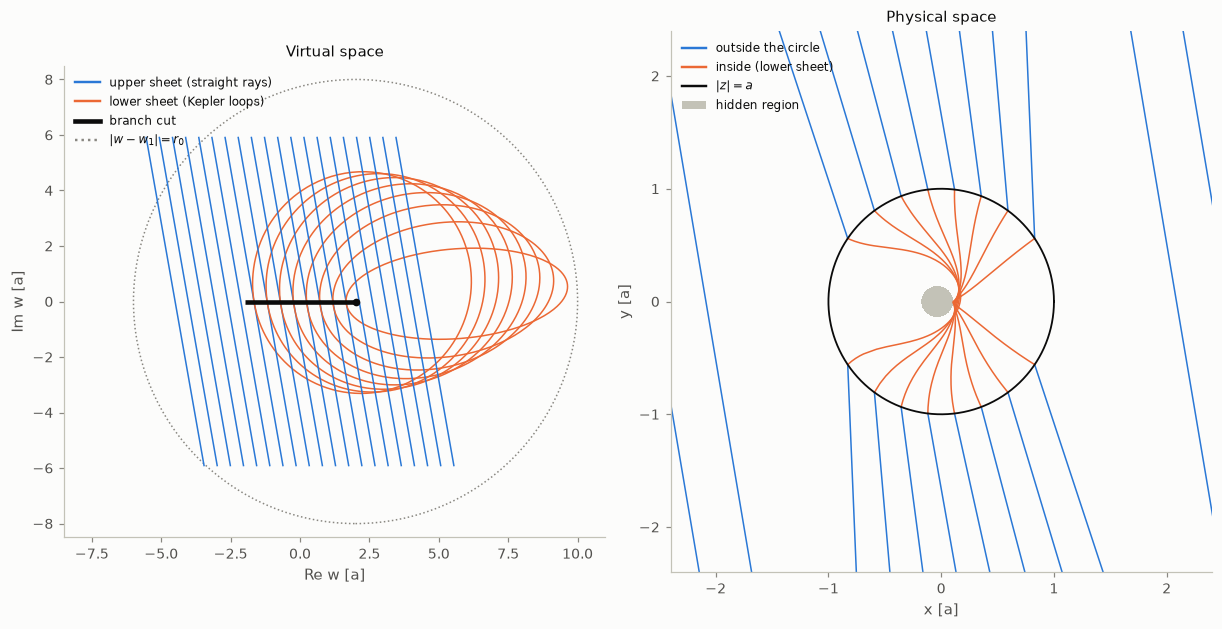

In [17]:
# --- figures for the cloak ---
PICK = [cloak_ray(xc, np.radians(-80)) for xc in np.linspace(-4.5, 4.5, 20)]
C_UP, C_LOW = CAT[0], CAT[1]                                     # upper-sheet rays blue, lower-sheet loops orange, in both panels
fig, axs = plt.subplots(1, 2, figsize=(11.0, 5.6))
ax = axs[0]
ax.add_patch(plt.Circle((w1, 0), r0, fc="none", ec=MUTED, ls=":", lw=1.0))
for R in PICK:
    for key in ("pre", "post"):
        if key in R: ax.plot(*R[key].T, color=C_UP, lw=1.0)
    if R["loop"] is not None: ax.plot(R["loop"][0], R["loop"][1], color=C_LOW, lw=1.0)
ax.plot([-2 * a_, 2 * a_], [0, 0], color=INK, lw=3.0, solid_capstyle="butt", zorder=5)
ax.plot([w1], [0], "o", color=INK, ms=4, zorder=6)
ax.plot([], [], color=C_UP, label="upper sheet (straight rays)"); ax.plot([], [], color=C_LOW, label="lower sheet (Kepler loops)")
ax.plot([], [], color=INK, lw=3, label="branch cut"); ax.plot([], [], color=MUTED, ls=":", label=r"$|w - w_1| = r_0$")
ax.set(xlim=(-8.5, 11), ylim=(-8.5, 8.5), aspect="equal", xlabel="Re w [a]", ylabel="Im w [a]", title="Virtual space"); ax.grid(False); ax.legend(loc="upper left", fontsize=8)
ax = axs[1]
ax.contourf(Xg, Yg, hidden.astype(float), levels=[0.5, 1.5], colors=[AXIS], zorder=1)
th = np.linspace(0, 2 * np.pi, 400); ax.plot(a_ * np.cos(th), a_ * np.sin(th), color=INK, lw=1.2, zorder=5)
for R in PICK:
    zp, zl, zq = physical(R)
    ax.plot(zp.real, zp.imag, color=C_UP, lw=1.0)
    if zq is not None: ax.plot(zq.real, zq.imag, color=C_UP, lw=1.0)
    if zl is not None: ax.plot(zl.real, zl.imag, color=C_LOW, lw=1.0)
ax.plot([], [], color=C_UP, label="outside the circle"); ax.plot([], [], color=C_LOW, label="inside (lower sheet)")
ax.plot([], [], color=INK, label=r"$|z| = a$"); ax.add_patch(plt.Rectangle((0, 0), 0, 0, fc=AXIS, label="hidden region"))
ax.set(xlim=(-2.4, 2.4), ylim=(-2.4, 2.4), aspect="equal", xlabel="x [a]", ylabel="y [a]", title="Physical space"); ax.grid(False); ax.legend(loc="upper left", fontsize=8)
plt.show()

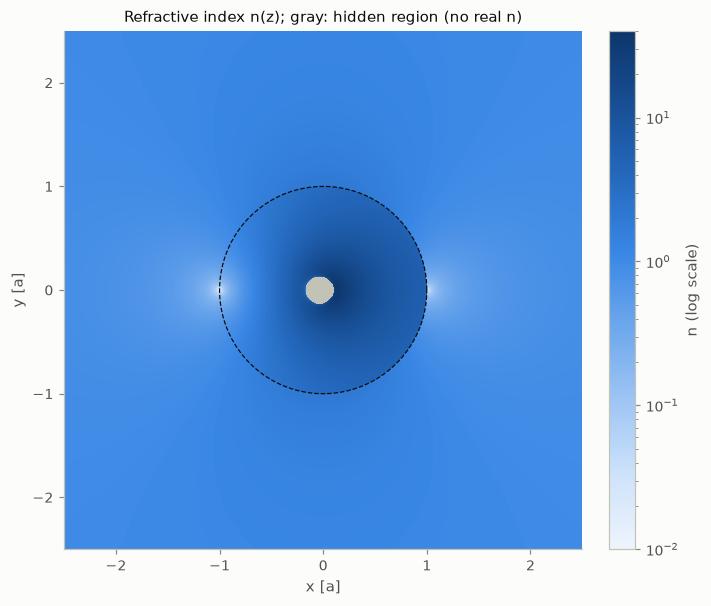

In [18]:
fig, ax = plt.subplots(figsize=(6.4, 5.4))
gx2 = np.linspace(-2.5, 2.5, 1000); X2, Y2 = np.meshgrid(gx2, gx2); N2 = n_phys(X2 + 1j * Y2)
cm = SEQ.copy(); cm.set_bad(AXIS)
im = ax.imshow(N2, extent=[-2.5, 2.5, -2.5, 2.5], cmap=cm, norm=LogNorm(vmin=1e-2, vmax=40))
ax.plot(a_ * np.cos(th), a_ * np.sin(th), color=INK, lw=0.8, ls="--")
ax.set(xlabel="x [a]", ylabel="y [a]", title="Refractive index n(z); gray: hidden region (no real n)", aspect="equal"); ax.grid(False)
fig.colorbar(im, ax=ax, label="n (log scale)"); plt.show()

## 6. What rays do not show

Rays say where light goes, not when it arrives, and a wave cares about the phase. The optical path excess of a ray is $\int n\,\mathrm dl$ between two planes $x=\mp X$ minus $2X$. For the invisible sphere the excess is $2\pi$ times the lens radius for every impact parameter, in line with the uniform delay of closed-loop profiles (book section 7, (7.28)). For the conformal cloak the rays through the cut are delayed by $\pi r_0$ and all other rays by nothing (by construction: they stay on the upper sheet where $n'=1$). This holds as well in physical space because $n\,\mathrm dl = n'\,|\mathrm dw|$.

What this means for waves, without computing any:

- **Invisible sphere.** A monochromatic wave behind it sees a uniform phase delay. The delay is harmless when the path excess plus any caustic (Maslov) phase picked up by the wave is a whole number of wavelengths. The excess alone is a whole number of wavelengths when $2\pi$ times the radius is an integer multiple of $\lambda$, which is the right condition only if the net caustic phase vanishes, as for the 2-D analog treated in notebook 04. The caustic phase differs between 2-D and 3-D, so for the sphere itself the condition is shifted: notebook 04, section 2.1, solves both cases for scalar waves and finds the cylinder nearly invisible at integer $k_0R$ and the sphere at half-integer $k_0R$. At other frequencies the device is invisible to rays and visible in the phase.
- **Conformal cloak.** Delayed and undelayed rays emerge side by side, with a sharp border between them (the edge of the bundle that meets the cut). All rays through the cut share the same delay $\pi r_0$, so in the ray picture the phase step at that border is the same for every ray and vanishes only at discrete frequencies (where $k_0\pi r_0$, corrected by one Maslov phase common to the bundle, is a multiple of $2\pi$). At other frequencies it is a phase slip, which the book (section 5) says may reveal the device. Whether a wave follows this ray prediction is not computed here.
- **Other wave-level caveats.** The index jumps across $|z|=a$ (the printed ratios show how large), so the interface reflects. $n$ vanishes at $z=\pm a$ on the outside, at $z=-a$ also on the inside, and at the edge of the hidden region (printed above), while on the inside it stays finite at $z=+a$; and the index varies strongly across the disk. A ray picture cannot say how large the resulting scattering is.

     b   excess / (2 pi)
  0.05       1.000000000
  0.20       1.000000000
  0.35       1.000000000
  0.50       1.000000000
  0.65       1.000000000
  0.80       1.000000000
  0.95       1.000000000
spread of the excess over all b: 6.3e-10
PASS  invisible sphere: optical path excess = 2 pi (lens radius 1), worst over b: got 6.29093e-10, target 0, |diff| 6.29e-10 <= 1e-06


delay of rays through the cut / (pi r0): min 1.000000000, max 1.000000001;  rays that miss it: 0.0 (by construction)
PASS  cloak: every ray through the cut is delayed by pi r0 (worst relative error): got 9.07306e-10, target 0, |diff| 9.07e-10 <= 1e-08


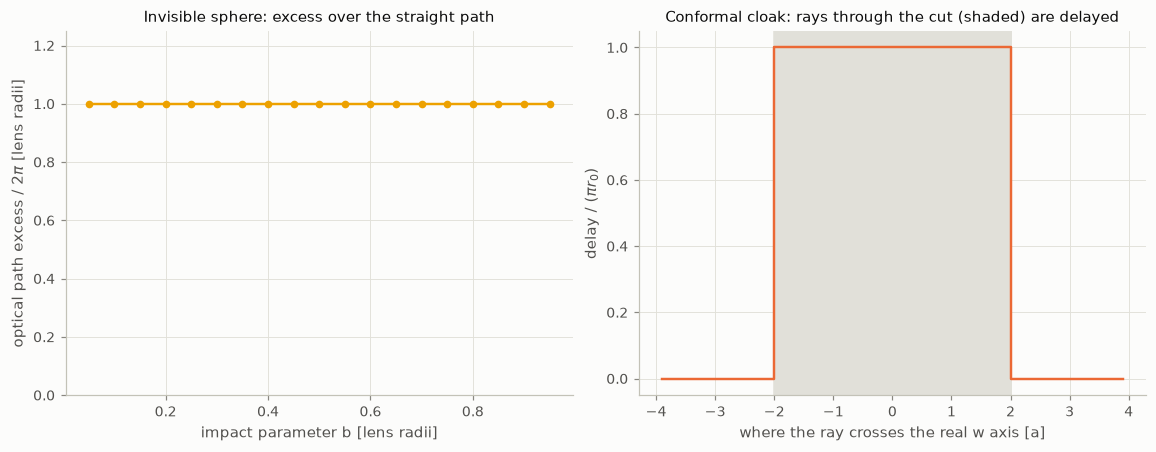

In [19]:
# --- optical path excess between the planes x = -X and x = +X ---
X = 3.0
def excess(name, b):
    s = lens_ray(name, b); pe, de = exit_state(s)
    return (s.y[0, 0] + X) + s.y[4, -1] + (X - pe[0]) / de[0] - 2 * X       # rim-to-plane vacuum legs + path in the lens - straight path
BE = np.linspace(0.05, 0.95, 19)
EX = {nm: np.array([excess(nm, b) for b in BE]) for nm in ["invisible sphere"]}
print(f"{'b':>6s}{'excess / (2 pi)':>18s}")
for i in range(0, len(BE), 3):
    print(f"{BE[i]:6.2f}{EX['invisible sphere'][i] / (2 * np.pi):18.9f}")
print(f"spread of the excess over all b: {np.ptp(EX['invisible sphere']):.1e}")
check("invisible sphere: optical path excess = 2 pi (lens radius 1), worst over b", np.max(np.abs(EX["invisible sphere"] - 2 * np.pi)), 1e-6)   # ray tolerances give ~1e-9

# the conformal cloak: delay of a family of parallel rays (direction -35 degrees) against the point where they cross the real w axis
XI = np.linspace(-3.9, 3.9, 40)
RD = [cloak_ray(x, np.radians(-35)) for x in XI]
DELAY = np.array([R["se"][4] if R["loop"] is not None else 0.0 for R in RD])   # rays that miss the cut stay on the upper sheet, n' = 1: zero by construction, not measured here
cut = np.abs(XI) < 2 * a_
print(f"delay of rays through the cut / (pi r0): min {DELAY[cut].min() / (np.pi * r0):.9f}, max {DELAY[cut].max() / (np.pi * r0):.9f};  rays that miss it: {np.abs(DELAY[~cut]).max():.1f} (by construction)")
check("cloak: every ray through the cut is delayed by pi r0 (worst relative error)", np.max(np.abs(DELAY[cut] / (np.pi * r0) - 1)), 1e-8)

fig, axs = plt.subplots(1, 2, figsize=(10.4, 4.0))
ax = axs[0]
ax.plot(BE, EX["invisible sphere"] / (2 * np.pi), "o-", color=PCOL["invisible sphere"], ms=4)
ax.set(xlabel="impact parameter b [lens radii]", ylabel=r"optical path excess / $2\pi$ [lens radii]", ylim=(0, 1.25), title="Invisible sphere: excess over the straight path")
ax = axs[1]
ax.step(XI, DELAY / (np.pi * r0), where="mid", color=CAT[1])
ax.axvspan(-2 * a_, 2 * a_, color=GRID, zorder=0)
ax.set(xlabel="where the ray crosses the real w axis [a]", ylabel=r"delay / ($\pi r_0$)", title="Conformal cloak: rays through the cut (shaded) are delayed"); plt.show()

## Summary

The tracer, an adaptive Runge-Kutta integrator with conservation laws as self-checks, reproduces every defining property: rim focusing (Luneburg), imaging of a point onto its antipode (fish-eye), retro-reflection (Eaton) and the straight-through loop of the invisible sphere. The deflection function computed from rays and by quadrature agree, and Luneburg's inversion closes the loop: it recovers the Eaton lens, the invisible sphere and the Luneburg lens, and it designs a right-angle bender that traced rays confirm. It fails, as it must, when $r(\rho)$ is not increasing or leaves the lens: a constant negative deflection is impossible for any medium (the deflection at the rim cannot be negative), while a weakly diverging lens whose deflection vanishes at the rim does exist.

The conformal cloak works as constructed: loops close, exit rays continue the entry rays, the loop path is $\pi r_0$ for every ray, and the physical rays outside the circle follow the pulled-back lines. What rays hide is the delay: uniform and equal to $2\pi$ times the radius for the invisible sphere, a step between the delayed bundle and the rest for the conformal cloak, equal for all delayed rays and removable in the ray picture only at discrete frequencies.

## Caveats and open ends

- Everything here is geometrical optics. Nothing says how well a wave with a given wavelength follows the rays near the singular points (the center of the invisible sphere and Eaton lens, the points $z=\pm a$ of the cloak, the square-root zero of $n'$ at the hidden boundary).
- The singular profiles need tighter integration than the brief's default tolerances; the table in section 2 documents the sensitivity. The deflection quadrature loses accuracy very close to the rim $b=1$, which is why the round trip in section 4 goes through a polynomial in $\sqrt{1-b}$.
- The bender's index is stored as a spline in $(\ln r,\ln n)$; its accuracy is verified by the ray test, not by an independent formula for $n(r)$.
- The hidden region is small compared with the disk, and the index inside the disk is large and rapidly varying. Nothing here estimates how well the loops could be realized.
- Existence and uniqueness for non-constant $\chi$ are only illustrated; the book treats them in section 8.

## References

- U. Leonhardt and T. Philbin, *Geometry and Light: The Science of Invisibility* (Dover, 2010): section 3 (Newtonian rays, (3.4)-(3.14)), section 5 (conformal maps, Riemann sheets, (5.9), (5.24)-(5.25), Fig. 2.19), section 6 (Eaton/Newton profile (6.8)), section 7 (closed loops, uniform delay (7.22)-(7.28)), section 8 (Luneburg's inversion (8.1), (8.12)-(8.16); ERRATA E1.4 for (8.18)-(8.19)), section 9 ((9.1)-(9.6), (9.10), (9.12), (9.13), (9.33); ERRATA E2.1 for the cubic).
- U. Leonhardt, "Optical conformal mapping", Science 312, 1777 (2006).